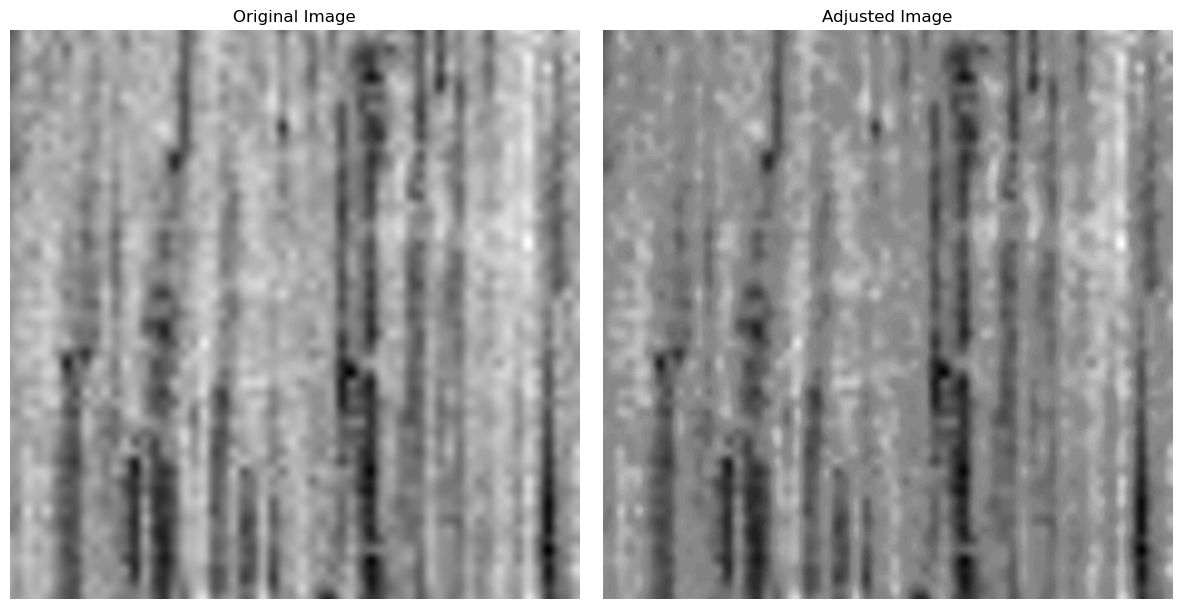

In [2]:
import cv2
import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

# 图像路径
image_path = "F:/B208/Sample/pku2025/0418/1-1-6/1-1-6.png"
adjusted_image_path = "F:/B208/Sample/pku2025/0418/1-1-6/ad1-1-6.png"
mapping_path = "F:/B208/Sample/pku2025/0418/1-1-6/1-1-6mo.txt"
block_gray_path = "F:/B208/Sample/pku2025/0418/1-1-6/1-1-6block_gray_compare.txt"

# 读取灰度图
# 读取灰度图
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# 将图像调整为 512x512
image = cv2.resize(image, (512, 512))

# 数据
# [density, standard_gray, current_gray]
data = [
    [8.314, 42.66, 89.71],
    [9.07, 44.086, 95.30],
    [9.826, 45.392, 103.41],
    [10.582, 46.173, 112.94],
    [12.09 , 48.678, 120.22]
]

# 构建映射函数
current_gray_values = [item[2] for item in data]
standard_gray_values = [item[1] for item in data]
interp_func = interp1d(current_gray_values, standard_gray_values, kind='linear', fill_value='extrapolate')
gray_to_standard_map = interp_func(np.arange(256))

# 映射图像
adjusted_image = gray_to_standard_map[image].astype(np.uint8)

# 保存调整后图像
cv2.imwrite(adjusted_image_path, adjusted_image)

# 保存灰度映射表
with open(mapping_path, 'w') as f:
    f.write("Original_Gray\tAdjusted_Gray\n")
    for orig, adj in enumerate(gray_to_standard_map):
        f.write(f"{orig}\t{adj:.2f}\n")

# ============ 切块计算平均灰度（原图和调整图） ============
BLOCK_H = 4
BLOCK_W = 4

with open(block_gray_path, 'w') as file:
    file.write("x_start\tx_end\ty_start\ty_end\tOriginal_Gray\tAdjusted_Gray\n")
    for y_start in range(0, image.shape[0] - BLOCK_H + 1, BLOCK_H):
        for x_start in range(0, image.shape[1] - BLOCK_W + 1, BLOCK_W):
            x_end = x_start + BLOCK_W
            y_end = y_start + BLOCK_H

            block_orig = image[y_start:y_end, x_start:x_end]
            block_adj = adjusted_image[y_start:y_end, x_start:x_end]

            orig_mean = np.mean(block_orig)
            adj_mean = np.mean(block_adj)

            file.write(f"{x_start}\t{x_end}\t{y_start}\t{y_end}\t{orig_mean:.2f}\t{adj_mean:.2f}\n")


# ============ 可视化 ============
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Adjusted Image")
plt.imshow(adjusted_image, cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()
